# Lab 2: Teach It 1s and 2s First, Then Introduce 3 — Watching Weights Reorganize

**MNIST internals series.** In [Lab 1](/posts/ml/labs/2026-10-19-lab-1-mnist-from-pixels-to-neural-network/) we established what a weight row *is*: a learned photograph of a class, contrast-carved against its rivals, painted by the update rule $W_c \leftarrow W_c - \eta\,\tfrac1N\sum (\hat p_c - y_c)\,x^\top$.

Now the experiment that motivated the series: **start the model in an impoverished world — only 1s and 2s exist — then let it discover 3.** This is *continual learning* in miniature, and it lets us watch, directly and quantitatively:

1. **Phase 1** — what two-class training actually creates (spoiler: the two rows come out near-mirror images, and that's not an accident),
2. **Phase 2** — how the old rows are re-carved when a new class arrives (the "1s/2s accuracy barely moves, but the weights definitely do" effect),
3. **Phase 3** — catastrophic forgetting: teach it *only* 3s afterwards and watch knowledge of 1 and 2 get actively repurposed, not merely fade; then the one-line fix (rehearsal).

Everything is the Lab 1 machinery: one softmax layer, plain SGD, float64 NumPy, checkpoints at every phase boundary.

## 0. Setup

Same model as Lab 1, verbatim — the only laboratory instrument here is the dataset's class composition. First, slice the data down to a two-class universe: all 1s and 2s, relabeled to output indices 0 and 1.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

from mnist_lab import (load_mnist, filter_classes, one_hot, show_grid, show_templates,
                       show_confusion, save_fig, save_ckpt, load_ckpt, manifest)

rng = np.random.default_rng(7)
x_train, y_train, x_test, y_test = load_mnist("data")
CKPT = Path("checkpoints/lab02"); FIGS = Path("figures/lab02"); FIGS.mkdir(parents=True, exist_ok=True)

class SoftmaxReg:
    """z = x @ W.T + b ; p = softmax(z) ; cross-entropy loss ; plain SGD. (Verbatim from Lab 1.)"""
    def __init__(self, n_in, n_classes, rng, scale=0.01):
        self.W = rng.normal(0, scale, size=(n_classes, n_in))
        self.b = np.zeros(n_classes)
    def logits(self, x):    return x @ self.W.T + self.b
    def probs(self, x):
        z = self.logits(x); z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z); return e / e.sum(axis=1, keepdims=True)
    def loss(self, x, y):
        p = self.probs(x)
        return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())
    def grad(self, x, y):
        p = self.probs(x)
        delta = p - one_hot(y, self.W.shape[0])
        return delta.T @ x / len(y), delta.mean(axis=0)
    def step(self, x, y, lr):
        gW, gb = self.grad(x, y)
        self.W -= lr * gW; self.b -= lr * gb
    def predict(self, x):   return self.logits(x).argmax(axis=1)
    def accuracy(self, x, y): return float((self.predict(x) == y).mean())

def per_class_acc(m, x, y, k):
    pred = m.predict(x)
    return [float((pred[y == c] == c).mean()) for c in range(k)]

def cos(u, v): return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

In [2]:
CLASSES_12 = [1, 2]
xtr12, ytr12, _ = filter_classes(x_train, y_train, CLASSES_12)
xte12, yte12, _ = filter_classes(x_test, y_test, CLASSES_12)
print(f"two-class universe: train {xtr12.shape[0]} {np.bincount(ytr12)}, test {xte12.shape[0]}")

model = SoftmaxReg(784, 2, rng)
BATCH, LR, EPOCHS = 256, 0.5, 3
t0 = time.perf_counter()
for epoch in range(EPOCHS):
    perm = rng.permutation(len(xtr12))
    perm = perm[: len(perm) // BATCH * BATCH]
    for i in perm.reshape(-1, BATCH):
        model.step(xtr12[i], ytr12[i], LR)
acc12 = model.accuracy(xte12, yte12)
print(f"trained {EPOCHS} epochs in {time.perf_counter()-t0:.1f}s | test accuracy on {{1,2}}: {acc12:.2%}")
save_ckpt(CKPT, "phase1_ones_twos", metrics={"test_acc_12": round(acc12, 4)}, W=model.W, b=model.b)

two-class universe: train 12700 [6742 5958], test 2167
trained 3 epochs in 0.1s | test accuracy on {1,2}: 99.22%


PosixPath('checkpoints/lab02/phase1_ones_twos.npz')

## 1. Two-class weights are mirror images

Theory first: softmax is invariant to adding the same constant to *all* logits, $p = \mathrm{softmax}(z) = \mathrm{softmax}(z + c\mathbf{1})$. So the model is free to slide both rows up and down together — only **differences** of rows drive predictions. With two classes, the entire decision is one scalar: $z_2 - z_1 = (W_2 - W_1)\cdot x + (b_2 - b_1) \gtrless 0$. The *cheapest* way to encode "1 vs 2" is therefore a single direction $\pm d$: row "2" $= +d$, row "1" $= -d$.

SGD, converging near the minimum-norm solution, goes exactly there. Let's measure it.

cosine(row_1, row_2)              = -0.9766
||row_1 + row_2|| / ||row_1||     = 0.218   (0 = perfectly antisymmetric)
saved figure -> figures/lab02/phase1_mirror.png


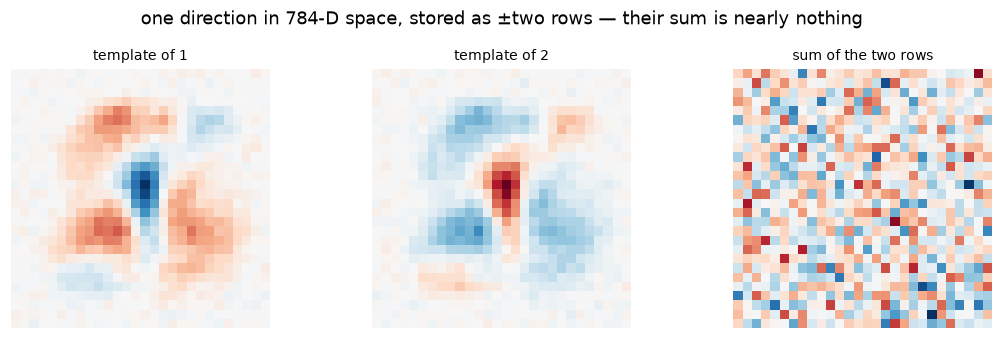

In [3]:
wA, wB = model.W    # row A = template of digit 1, row B = template of digit 2
print(f"cosine(row_1, row_2)              = {cos(wA, wB):+.4f}")
print(f"||row_1 + row_2|| / ||row_1||     = {np.linalg.norm(wA + wB) / np.linalg.norm(wA):.3f}   (0 = perfectly antisymmetric)")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.1))
for ax, v, ttl in ((axes[0], wA, "template of 1"),
                   (axes[1], wB, "template of 2"),
                   (axes[2], wA + wB, "sum of the two rows")):
    lim = np.abs(v).max()
    ax.imshow(v.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(ttl, fontsize=9); ax.axis("off")
fig.suptitle("one direction in 784-D space, stored as ±two rows — their sum is nearly nothing")
fig.tight_layout(); save_fig(fig, FIGS / "phase1_mirror.png"); plt.show()

The residual mass in "sum of the two rows" is the shared structure all digits have (the central ink channel) — useless for telling them apart, so it goes un-learned. **Weights record contrast, not appearance.**

### What does this model do with a 3?

It has no "I don't know" neuron. A 3 *must* come out as 1 or 2. Purely from pixel overlap you'd guess most 3s get called "2" — the loops sit in the same places. Let's check.

what the {1,2}-model calls every handwritten 3 in the test set:
  -> classified as 1: 23.7%
  -> classified as 2: 76.3%
  median logit margin z_2 - z_1 = +2.40


saved figure -> figures/lab02/threes_in_a_two_class_world.png


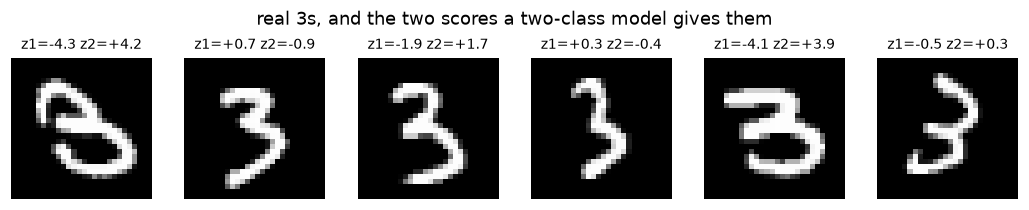

In [4]:
x3 = x_test[y_test == 3]
p3 = model.predict(x3)
print("what the {1,2}-model calls every handwritten 3 in the test set:")
print(f"  -> classified as 1: {(p3 == 0).mean():.1%}")
print(f"  -> classified as 2: {(p3 == 1).mean():.1%}")
z3 = model.logits(x3)
print(f"  median logit margin z_2 - z_1 = {np.median(z3[:, 1] - z3[:, 0]):+.2f}")

fig = show_grid(x3[:6], titles=[f"z1={a:+.1f} z2={b:+.1f}" for a, b in z3[:6]], ncols=6,
                suptitle="real 3s, and the two scores a two-class model gives them")
save_fig(fig, FIGS / "threes_in_a_two_class_world.png"); plt.show()

## 2. Introduce the 3

Now add a third output row (random init ~ N(0, 0.01)) and keep training on all of {1, 2, 3} — **old rows are NOT frozen**, they keep moving. What should we expect?

The 2 and the 3 share real estate: both draw a right-side vertical-ish stroke and middle curves. Before 3 arrived, row "2"'s blueprint covered a lot of "3-ish" pixels positively. Once 3s are in the training data, every 3 that scores high on row "2" paints $-\hat p_2\,x$ there (the gradient rule from Lab 1). Watch the per-class accuracies, then look at the before/after templates and the change map $\Delta W$.

In [5]:
CLASSES_123 = [1, 2, 3]
xtr, ytr, _ = filter_classes(x_train, y_train, CLASSES_123)
xte, yte, _ = filter_classes(x_test, y_test, CLASSES_123)

W_before = model.W.copy()

model3 = SoftmaxReg(784, 3, rng)
model3.W = np.vstack([model.W, rng.normal(0, 0.01, (1, 784))])   # keep old rows, append a blank-ish one
model3.b = np.append(model.b, 0.0)

hist = [(0, *per_class_acc(model3, xte, yte, 3))]
step = 0
for epoch in range(1, 4):
    perm = rng.permutation(len(xtr))
    perm = perm[: len(perm) // BATCH * BATCH]
    for i in perm.reshape(-1, BATCH):
        model3.step(xtr[i], ytr[i], LR)
        step += 1
    accs = per_class_acc(model3, xte, yte, 3)
    hist.append((step, *accs))
    save_ckpt(CKPT, f"phase2_epoch{epoch}", step=step,
              metrics={f"acc_{c}": round(a, 4) for c, a in zip(CLASSES_123, accs)},
              W=model3.W, b=model3.b)

print("  step |  acc(1)   acc(2)   acc(3)")
for s, a1, a2, a3 in hist:
    print(f"{s:>6} |  {a1:.4f}   {a2:.4f}   {a3:.4f}")

  step |  acc(1)   acc(2)   acc(3)
     0 |  0.9938   0.9903   0.0297
    73 |  0.9921   0.9641   0.9743
   146 |  0.9930   0.9516   0.9812
   219 |  0.9912   0.9399   0.9861


saved figure -> figures/lab02/phase2_deltas.png


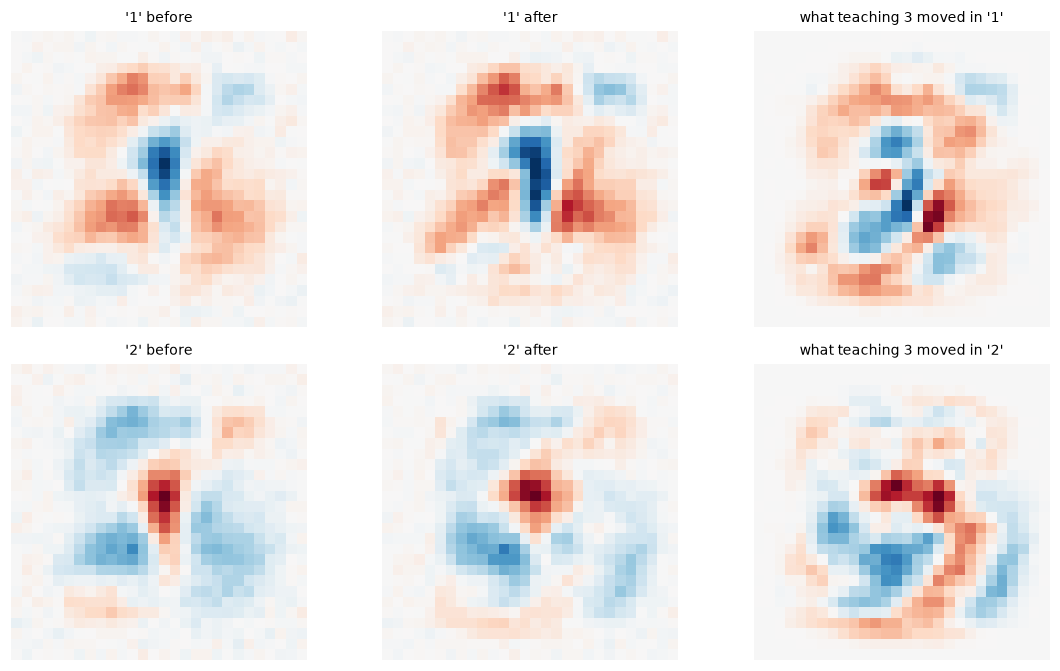

saved figure -> figures/lab02/phase2_templates.png


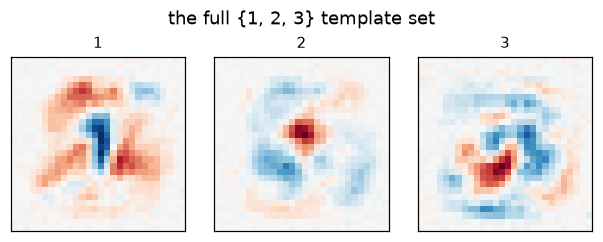

template of '1': cos(before, after) = +0.8990 | ||delta||/||W|| = 0.648
template of '2': cos(before, after) = +0.8431 | ||delta||/||W|| = 0.777
saved figure -> figures/lab02/phase2_confusion.png


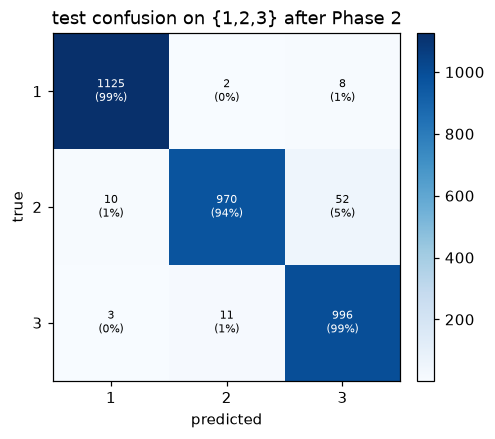

In [6]:
W_after = model3.W
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.2))
pairs = [("'1' before", W_before[0]), ("'1' after", W_after[0]), ("what teaching 3 moved in '1'", W_after[0] - W_before[0]),
         ("'2' before", W_before[1]), ("'2' after", W_after[1]), ("what teaching 3 moved in '2'", W_after[1] - W_before[1])]
for ax, (ttl, v) in zip(axes.flat, pairs):
    lim = np.abs(v).max()
    ax.imshow(v.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(ttl, fontsize=9); ax.axis("off")
fig.tight_layout(); save_fig(fig, FIGS / "phase2_deltas.png"); plt.show()

fig = show_templates(W_after, row_labels=CLASSES_123, suptitle="the full {1, 2, 3} template set")
save_fig(fig, FIGS / "phase2_templates.png"); plt.show()

for c in range(2):
    print(f"template of '{CLASSES_123[c]}': cos(before, after) = {cos(W_before[c], W_after[c]):+.4f}"
          f" | ||delta||/||W|| = {np.linalg.norm(W_after[c] - W_before[c]) / np.linalg.norm(W_before[c]):.3f}")

pred = model3.predict(xte)
cm3 = np.zeros((3, 3), dtype=int)
for t, p in zip(yte, pred):
    cm3[t, p] += 1
fig, ax = plt.subplots(figsize=(4.8, 4.1))
show_confusion(cm3, ["1", "2", "3"], ax=ax, title="test confusion on {1,2,3} after Phase 2")
save_fig(fig, FIGS / "phase2_confusion.png"); plt.show()

### Reading Phase 2's numbers

The accuracies say: teaching 3 was *nearly free* for 1s (99.4% → 99.1%) but cost the 2s real rent (99.0% → 94.0%), while 3s shot from 2.97% (random new row) to 98.6%. Exactly the digit that shares territory with the newcomer pays.

Meanwhile the templates tell a bigger story: $\|\Delta W\|/\|W\| = 0.65$ for the "1" row and $0.78$ for the "2" row — the matrix was rewritten by more than half its magnitude, and cosine(before, after) fell to 0.90 / 0.84. **Same behavior, different weights.** The lesson: "the model still gets 99% on 1s and 2s" is a *statement about the decision boundary*, not about the weights. Net of the cosmetic movement, the Δ-maps show the "2" row ceding middle-right territory to the newborn "3" row.

## 3. Catastrophic forgetting — and what "forgetting" actually looks like

Now the counterfactual that makes continual learning famous. Roll back to the **Phase 1 checkpoint** (knows 1s and 2s perfectly, has never seen a 3). Add the third row. Then train on **only 3s**.

The painting rule predicts something sharper than "the old knowledge fades": a batch full of 3s applies gradient $-\hat p_c\,x$ to the old rows — they are *actively pushed to become "anti-3" detectors*. Row 1 and row 2 don't just decay toward zero; they get repurposed. Measure four things as training proceeds: accuracy on 1s, on 2s, on 3s, and what the old templates look like afterwards.

Then **rehearsal**: same procedure, but each batch is a mixture — mostly 3s plus a small ration of 1s and 2s. One ingredient, and the catastrophe disappears.

In [7]:
base = load_ckpt(CKPT / "phase1_ones_twos.npz")   # roll back: model as of end of Phase 1

def make3():
    m = SoftmaxReg(784, 3, rng)
    m.W = np.vstack([base["W"], np.zeros((1, 784))])   # exact Phase-1 weights + a blank third row
    m.b = np.append(base["b"], 0.0)
    return m

def run_phase(m, xs, ys, steps=600, batch=64, lr=0.2, log_every=50, seed=0):
    r = np.random.default_rng(seed)
    rows = [(0, *per_class_acc(m, xte, yte, 3))]
    for s in range(1, steps + 1):
        i = r.integers(0, len(xs), batch)
        m.step(xs[i], ys[i], lr)
        if s % log_every == 0:
            rows.append((s, *per_class_acc(m, xte, yte, 3)))
    return np.array(rows)

x3tr = x_train[y_train == 3]; y3tr = np.full(len(x3tr), 2)     # only 3s, relabeled index 2

# --- Experiment B: only 3s ---
modelB = make3()
hB = run_phase(modelB, x3tr, y3tr, seed=1)
save_ckpt(CKPT, "phase3B_only3",
          metrics={f"acc_{c}": round(a, 4) for c, a in zip(CLASSES_123, hB[-1, 1:])},
          W=modelB.W, b=modelB.b)

# --- Experiment C: 3s + rehearsal ration of 1s/2s ---
x12_sub, y12_sub = xtr12[::4], ytr12[::4]
xmix = np.concatenate([x3tr, x12_sub]);  ymix = np.concatenate([y3tr, y12_sub])
modelC = make3()
hC = run_phase(modelC, xmix, ymix, seed=1)
save_ckpt(CKPT, "phase3C_rehearsal",
          metrics={f"acc_{c}": round(a, 4) for c, a in zip(CLASSES_123, hC[-1, 1:])},
          W=modelC.W, b=modelC.b)

print("final per-digit test accuracies (start | B: only 3s | C: rehearsal):")
for c, d in enumerate(CLASSES_123):
    print(f"  {d}s: {hB[0, c+1]:.3f} | {hB[-1, c+1]:.3f} | {hC[-1, c+1]:.3f}")

final per-digit test accuracies (start | B: only 3s | C: rehearsal):
  1s: 0.994 | 0.000 | 0.981
  2s: 0.989 | 0.000 | 0.926
  3s: 0.043 | 1.000 | 0.993


saved figure -> figures/lab02/phase3_curves.png


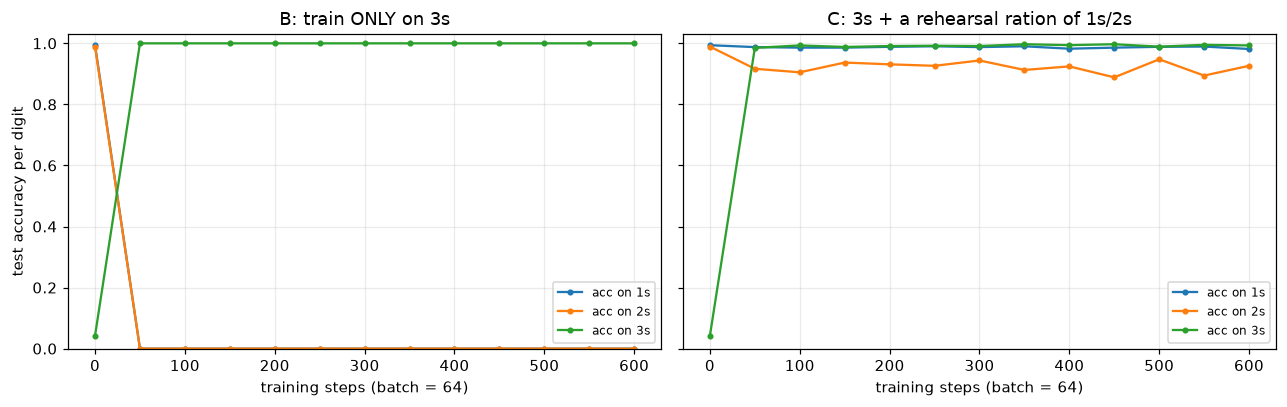

saved figure -> figures/lab02/phase3_templates_B.png


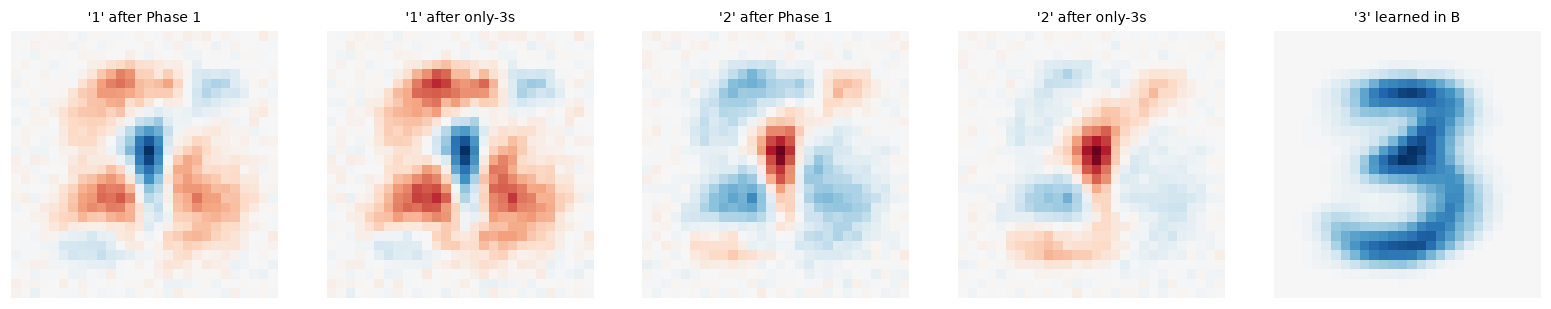

how far the old rows were dragged (cos vs their Phase-1 selves):
  row '1': +0.9748
  row '2': +0.8634


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 3.8), sharey=True)
for ax, h, ttl in ((axes[0], hB, "B: train ONLY on 3s"),
                   (axes[1], hC, "C: 3s + a rehearsal ration of 1s/2s")):
    for c, d in enumerate(CLASSES_123):
        ax.plot(h[:, 0], h[:, c + 1], "-o", ms=3, lw=1.5, label=f"acc on {d}s")
    ax.set_xlabel("training steps (batch = 64)"); ax.set_title(ttl)
    ax.set_ylim(0, 1.03); ax.grid(alpha=.25); ax.legend(fontsize=8)
axes[0].set_ylabel("test accuracy per digit")
fig.tight_layout(); save_fig(fig, FIGS / "phase3_curves.png"); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(14.5, 2.8))
panels = [(base["W"][0], "'1' after Phase 1"), (modelB.W[0], "'1' after only-3s"),
          (base["W"][1], "'2' after Phase 1"), (modelB.W[1], "'2' after only-3s"),
          (modelB.W[2], "'3' learned in B")]
for ax, (v, ttl) in zip(axes, panels):
    lim = np.abs(v).max()
    ax.imshow(v.reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_title(ttl, fontsize=9); ax.axis("off")
fig.tight_layout(); save_fig(fig, FIGS / "phase3_templates_B.png"); plt.show()

print("how far the old rows were dragged (cos vs their Phase-1 selves):")
for c, d in ((0, 1), (1, 2)):
    print(f"  row '{d}': {cos(base['W'][c], modelB.W[c]):+.4f}")

## 3b. Why did the old knowledge lose? Peek at the numbers

Here is the subtle part that the accuracy curves hide. Compare the old weight rows *before and after* Experiment B, mechanically — norms, biases, and (already printed above) cosine to their Phase-1 selves:

In [9]:
print("row diagnostics — Phase 1 -> after training on ONLY 3s:")
print("class   ||W||           b")
for c, d in enumerate(CLASSES_123):
    n0 = np.linalg.norm(base["W"][c]) if c < 2 else 0.0
    b0 = float(base["b"][c]) if c < 2 else 0.0
    print(f"  {d}:  {n0:5.2f} -> {np.linalg.norm(modelB.W[c]):5.2f}   {b0:+.2f} -> {modelB.b[c]:+.2f}")

x1 = xte[yte == 0]                       # all real test 1s (class index 0 = digit 1)
z1s = x1 @ modelB.W.T + modelB.b
print(f"\non the {len(x1)} real test 1s:  mean z('1' row) = {z1s[:, 0].mean():+.2f}   z('2' row) = {z1s[:, 1].mean():+.2f}   z('3' row) = {z1s[:, 2].mean():+.2f}")
print(f"the '1' row is still the argmax on {(z1s.argmax(1) == 0).mean():.1%} of them")

row diagnostics — Phase 1 -> after training on ONLY 3s:
class   ||W||           b
  1:   1.79 ->  1.81   +0.14 -> +0.07
  2:   1.81 ->  1.91   -0.14 -> -0.28
  3:   0.00 ->  1.36   +0.00 -> +0.21

on the 1135 real test 1s:  mean z('1' row) = +0.82   z('2' row) = -6.41   z('3' row) = +5.42
the '1' row is still the argmax on 0.0% of them


Neither the directions (cos ≈ 0.97, 0.86) nor the norms (1.8 → 1.8, 1.9) of the old rows were destroyed. Look at the rightmost panel of the figure above instead: **the freshly learned "3" template is pure blue — it has no red halo at all.** It trained 600 steps on nothing but 3s, so every update painted *positive* ink, $(1-\hat p_3)\,x$; it never once had a rival to suppress.

The old rows, by contrast, carry heavy red halos from their war with each other — so when a real "1" strays a pixel into the old "1" template's red zone, it pays full price, while the innocent "3" row charges nothing. Result, measured on all 1,135 test 1s: the virgin "3" row scores $z_3 \approx +5.4$ while the actual "1" row ekes out $z_1 \approx +0.8$ (and its mirror, the "2" row, drags $-6.4$ — exactly the antisymmetry from §1 working *against* itself). Not one test "1" is ever the argmax. The newcomer wins not by knowing more about 3s, but by **never having learned to say no**.

That is what forgetting *is* here — not erasure, but out-bidding: the veteran classes' hard-won red ink turns into a liability the moment an un-criticized class enters the same tournament. Grown-up continual learning has an entire literature on exactly this pathological "new class logit inflation" (e.g. *bias correction* — Wu et al., [BiC, CVPR 2019](https://openaccess.thecvf.com/content_CVPR_2019/html/Wu_Large_Scale_Incremental_Learning_CVPR_2019_paper.html)) and on protecting the red halos (**EWC**, below).

## 4. What we actually learned

**Softmax rows encode comparisons, not portraits.** With two classes the machine literally stores one direction twice with opposite signs — the "sum" panel above is almost blank. The unit of knowledge in $W$ is the *boundary between classes*, not the class itself.

**Adding a class re-carves old weights while barely touching old accuracy.** Phase 2: 1s untouched (99.4% → 99.1%), 2s lost ~5 points (99.0% → 94.0%), 3s learned to 98.6% — while the old rows were rewritten by 65–78% of their norm. Knowledge in a neural net is *redundant and continuously maintained*: many parameter settings classify 1s and 2s equally well, and SGD happily surfs among them when a new demand arrives — silent to any metric that only watches accuracy.

**Forgetting here was not erasure — it was out-bidding.** After 600 steps of only-3s, accuracy on 1s and 2s was *exactly 0%*, yet the old rows' directions survived (cos ≈ 0.97, 0.86) with near-intact norms. The model forgot because the rival-free "3" row — all blue, no suppression halo — outscores the contrast-carved veterans even on their own digits. This is the same pathology large models show when fine-tuning inflates the logits of whatever you trained last: the fix in both worlds is to keep the old knowledge *active* while the new learns (rehearsal below) or to penalize drift of important weights (EWC).

**A trivially small memory of the past prevents it.** Rehearsal — a 1-in-4 ration of 1s and 2s mixed into the batch stream — held the old digits at 98.1% / 92.6% while 3s still reached 99.3%. The old rows kept getting their $(1 - \hat p)x$ reinforcement often enough that their red halos survived, so the new class had to grow its own halo too and couldn't free-ride. Scale this idea up and you get the whole continual-learning toolbox: replay buffers, and its parametric cousin **EWC** (penalize moving weights that mattered for old tasks).

**Curated reading:**

- McCloskey & Cohen, [*Catastrophic Interference in Connectionist Networks*](https://doi.org/10.1016/S0079-7421(08)60536-8) (1989) — the original observation.
- French, [*Catastrophic forgetting in connectionist networks*](https://doi.org/10.1016/S1364-6613(99)01294-2), Trends in Cognitive Sciences (1999).
- Kirkpatrick et al., [*Overcoming catastrophic forgetting in neural networks* (EWC)](https://www.pnas.org/doi/10.1073/pnas.1611835114), PNAS 2017 — DeepMind's weight-importance regularizer.
- On why fine-tuned LLMs forget pretraining skills unless old data is mixed in: same math, larger canvas — the $\hat p - y$ update doesn't know or care which task an example came from.

**Next lab:** add a hidden layer. Rows of $W^{(1)}$ stop being digit photographs and become *features* — edgelets and stroke fragments that no longer correspond to classes — and we will need a new instrument (activation maximization) to see them. That is where the Distill literature begins.

---

### Reproduce

```bash
cd labs/ml/mnist-internals
source .venv/bin/activate
jupyter lab     # open 02_teach_1_2_then_3.ipynb
```

Artifacts: `checkpoints/lab02/` (`phase1_ones_twos.npz`, `phase2_epoch{1,2,3}.npz`, `phase3B_only3.npz`, `phase3C_rehearsal.npz`, + `manifest.json`), `figures/lab02/*.png`.

In [10]:
print("checkpoints written this lab:")
for e in manifest(CKPT):
    print(f"  {e['name']:<18} step={str(e['step']):<5} metrics={e['metrics']}")

checkpoints written this lab:
  phase1_ones_twos   step=None  metrics={'test_acc_12': 0.9922}
  phase2_epoch1      step=73    metrics={'acc_1': 0.9921, 'acc_2': 0.9641, 'acc_3': 0.9743}
  phase2_epoch2      step=146   metrics={'acc_1': 0.993, 'acc_2': 0.9516, 'acc_3': 0.9812}
  phase2_epoch3      step=219   metrics={'acc_1': 0.9912, 'acc_2': 0.9399, 'acc_3': 0.9861}
  phase3B_only3      step=None  metrics={'acc_1': 0.0, 'acc_2': 0.0, 'acc_3': 1.0}
  phase3C_rehearsal  step=None  metrics={'acc_1': 0.9815, 'acc_2': 0.9264, 'acc_3': 0.9931}
